<h1 style="text-align:center;">
Distribución territorial de establecimientos públicos de salud en la Provincia de Buenos Aires
</h1>



<p style="text-align:center;">
Bioq. María Jimena Benito Nacir
</p>

<p style="text-align:center;">
Junio 2026
</p>

<hr>

## Introducción

La distribución territorial de los establecimientos públicos de salud constituye un aspecto relevante para analizar el acceso potencial de la población a los servicios sanitarios. En la Provincia de Buenos Aires, los partidos presentan diferencias importantes en su cantidad de habitantes, superficie y grado de concentración urbana, lo que puede generar desigualdades en la disponibilidad territorial de establecimientos de salud.

En este contexto, el presente trabajo propone un análisis geoespacial a nivel de partido, integrando información sobre establecimientos públicos de salud, límites geográficos y población, con el fin de explorar si la distribución de la oferta sanitaria acompaña la distribución poblacional.

## Objetivo

Analizar la distribución territorial de los establecimientos públicos de salud en la Provincia de Buenos Aires y evaluar su relación con la población por partido, mediante indicadores y visualizaciones geoespaciales.

## Fuentes de datos

Para el desarrollo del trabajo se utilizaron tres datasets del portal oficial de Datos Abiertos de la Provincia de Buenos Aires:

- **Establecimientos públicos de salud:** contiene información georreferenciada de establecimientos nacionales, provinciales y municipales. Se utiliza para analizar su distribución territorial.

- **Límites de partidos de la Provincia de Buenos Aires:** contiene cartografía oficial de los partidos bonaerenses. Se utiliza como base geográfica para la representación espacial y el análisis territorial.

- **Población por partido:** contiene datos de población, censos y proyecciones para el período 2010-2025. Se utiliza para calcular indicadores relativos a la cobertura territorial de establecimientos de salud en función de la población.

## Referencias

- Gobierno de la Provincia de Buenos Aires. Portal de Datos Abiertos. Dataset Establecimientos públicos de salud.
- Gobierno de la Provincia de Buenos Aires. Portal de Datos Abiertos. Dataset Límites de partidos de la Provincia de Buenos Aires.
- Gobierno de la Provincia de Buenos Aires. Portal de Datos Abiertos. Dataset Población, censos 2010 y 2022, y proyecciones 2010-2025.
- GeoPandas Documentation.
- Pandas Documentation.
- Matplotlib Documentation.


## Carga de librerías

In [ ]:
# Manejo y análisis de datos
import pandas as pd

# Gestión de rutas
from pathlib import Path

# Análisis geoespacial
import geopandas as gpd

# Visualización de datos
import matplotlib.pyplot as plt

# Visualización de mapas interactivos
import folium



## Carga de datasets

En esta sección se cargan los datasets que serán utilizados en el análisis:

- Establecimientos de salud
- Límites de partidos
- Población por partido

In [ ]:
# Conexión con Google Drive (solo necesaria al ejecutar en Google Colab)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Definición de la carpeta base del proyecto
# Se utiliza para construir rutas relativas a los datasets y facilitar la ejecución del notebook en diferentes equipos

BASE_DIR = Path('/content/drive/MyDrive')


In [ ]:
print("BASE_DIR:", BASE_DIR)
print("Existe carpeta datos:", (BASE_DIR / "datos").exists())

carpeta_salud = BASE_DIR / "datos" / "establecimientos_salud_publicos"
print("Existe carpeta salud:", carpeta_salud.exists())

print("\nArchivos dentro de establecimientos_salud_publicos:")
for archivo in carpeta_salud.iterdir():
    print(archivo.name)

BASE_DIR: /content/drive/MyDrive
Existe carpeta datos: True
Existe carpeta salud: True

Archivos dentro de establecimientos_salud_publicos:
Establecimientos_salud_publicos_alta_al20220721.cpg
Establecimientos_salud_publicos_alta_al20220721.prj
Establecimientos_salud_publicos_alta_al20220721.qmd
Establecimientos_salud_publicos_alta_al20220721.shp
Establecimientos_salud_publicos_alta_al20220721.shx
Establecimientos_salud_publicos_alta_al20220721.dbf
Establecimientos_salud_publicos_alta_al20220721.geojson


In [ ]:
# Establecimientos de salud públicos
ruta_salud = BASE_DIR / "datos"/ "establecimientos_salud_publicos" / "Establecimientos_salud_publicos_alta_al20220721.shp"
salud = gpd.read_file(ruta_salud)

# Límites de partidos
ruta_partidos = BASE_DIR / "datos"/ "limites-partidos" / "partidos.geojson"
partidos = gpd.read_file(ruta_partidos)

# Población por partido
ruta_poblacion = BASE_DIR /"datos"/ "proyecciones-poblacion-2010_2025.csv"
poblacion = pd.read_csv(ruta_poblacion)


## Exploración inicial de los datos

### Estructura de los datasets
Se realizó una revisión inicial de cada dataset de forma individual utilizando las funciones `shape` y `head()`. Esta estrategia permitió verificar la correcta carga de los datos y visualizar con mayor claridad su estructura, dimensiones y contenido.

La función `shape` permite conocer la cantidad de registros y variables presentes en cada dataset, mientras que `head()` muestra las primeras filas para inspeccionar su estructura y detectar posibles inconsistencias de manera preliminar.


In [ ]:
print("Establecimientos de salud:")
print(salud.shape)
salud.head()


Establecimientos de salud:
(2840, 23)


,id,lat,long,fna,gna,nam,sag,cpd,cnr,cde,...,cat,dom,tel,sse,nrs,cp1,nor,mod,mai,geometry
0,1.0,-33.330449,-60.214505,Centro de Medicina Preventiva Dr. C. Ferreyra,Centro,de Medicina Preventiva Dr. C. Ferreyra,Dis. Ministerio de Salud BA,76300040,5.006763e+13,763,...,C.A.P.S,Rivadavia N° 45,0336-5408830/36,Público,IV,2900,Centro de Medicina Preventiva Dr. Carlos Ferre...,Sin internación,None,POINT (-60.2145 -33.33045)
1,2.0,-33.338516,-60.198464,C.A.P.S. San Roque,C.A.P.S.,San Roque,Dis. Ministerio de Salud BA,76300236,5.006763e+13,763,...,C.A.P.S,Cochabamba y Colón Bo. Cavalli,-,Público,IV,2900,Centro Atención Primaria Socio Sanitaria San R...,Sin internación,None,POINT (-60.19846 -33.33852)
2,3.0,-33.315692,-60.243740,Centro de Atención 24 horas E. Barbarito,Centro de Atención 24 horas,E. Barbarito,Dis. Ministerio de Salud BA,76300431,5.006763e+13,763,...,C.A.P.S,Pastor Naranjo N° 898 Bo. 25 de Mayo,-,Público,IV,2900,CENTRO DE ATENCIÓN 24 HS. ENF. BARBARITO,Sin internación,None,POINT (-60.24374 -33.31569)
3,5.0,-33.298810,-60.263766,C.A.P.S. H. R. Cardinale,C.A.P.S.,H. R. Cardinale,Dis. Ministerio de Salud BA,76300473,5.006763e+13,763,...,C.A.P.S,Schubert N° 1783 Bo. Las Mellizas,-,Público,IV,2900,Centro Atención Primaria Socio Sanitaria Raúl ...,Sin internación,None,POINT (-60.26377 -33.29881)
4,6.0,-33.355929,-60.206218,Centro de Atención 24 horas H. Panzardi,Centro de Atención 24 horas,H. Panzardi,Dis. Ministerio de Salud BA,76300546,5.006763e+13,763,...,C.A.P.S,Segundo García y Brown Bo. Del Carmen,None,Público,IV,2900,CENTRO DE ATENCIÓN 24 HS HUGO PANZARDI,Sin internación,None,POINT (-60.20622 -33.35593)


La base de datos de establecimientos de salud contiene 2.840 registros y 23 variables. En las primeras filas se observan campos de identificación, coordenadas geográficas (`lat`, `long`) y datos descriptivos del establecimiento, como nombre, dependencia, categoría y domicilio. La presencia de información geográfica y de la columna `geometry` confirma que el dataset se encuentra preparado para realizar análisis espaciales y representar la ubicación de los establecimientos públicos de salud en la Provincia de Buenos Aires.

Variables principales utilizadas en el análisis:

- `lat`, `long`: coordenadas geográficas del establecimiento.
- `geometry`: ubicación espacial del establecimiento en formato punto.
- `nam`: nombre del establecimiento.
- `cat`: categoría del establecimiento.

In [ ]:
print("Límites de partidos:")
print(partidos.shape)
partidos.head()



Límites de partidos:
(143, 9)


,cca,cde,fna,gna,nam,sag,ara3,arl,geometry
0,045,06357,Partido de General Pueyrredón,Partido,General Pueyrredón,ARBA,1463.50,1460.74,"MULTIPOLYGON (((-57.54 -38.06, -57.53 -38.05, ..."
1,055,06441,Partido de La Plata,Partido,La Plata,ARBA,892.63,942.23,"MULTIPOLYGON (((-58.14 -34.99, -58.13 -35, -58..."
2,070,06427,Partido de La Matanza,Partido,La Matanza,ARBA,328.19,329.22,"MULTIPOLYGON (((-58.58 -34.65, -58.58 -34.65, ..."
3,030,06260,Partido de Esteban Echeverría,Partido,Esteban Echeverría,ARBA,120.45,120.22,"MULTIPOLYGON (((-58.51 -34.73, -58.51 -34.73, ..."
4,074,06560,Partido de Moreno,Partido,Moreno,ARBA,186.05,186.13,"MULTIPOLYGON (((-58.78 -34.56, -58.77 -34.56, ..."


La base de límites de partidos contiene 143 registros y 9 variables. Incluye información de identificación territorial, nombre del partido, superficie y geometría tipo `MULTIPOLYGON`. Este dataset se utilizará como capa base para integrar y representar espacialmente la información de población y establecimientos de salud.

Variables principales utilizadas en el análisis:

- `nam`: nombre del partido.
- `ara3`: superficie del partido según la capa territorial.
- `geometry`: geometría espacial del partido utilizada para la representación cartográfica.

In [ ]:
print("Población por partido:")
print(poblacion.shape)
poblacion.head()

Población por partido:
(1203, 34)


,municipio_id,municipio_nombre,2010,2011,2012,2013,2014,2015,2016,2017,...,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32,Unnamed: 33
0,6.0,Total,15625084,15909607.0,16100618.0,16289599.0,16476149.0,16659931.0,16841135.0,17020012.0,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6007.0,Adolfo Alsina,17072,17249.0,17276.0,17303.0,17330.0,17356.0,17382.0,17407.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,6014.0,Adolfo Gonzales Chaves,12047,12142.0,12116.0,12091.0,12065.0,12040.0,12016.0,11992.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,6021.0,Alberti,10654,10773.0,10799.0,10824.0,10850.0,10875.0,10900.0,10924.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,6028.0,Almirante Brown,552902,561349.0,565509.0,569911.0,574263.0,578513.0,582541.0,586564.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


La base de población por partido contiene 1.203 registros y 34 variables. Incluye el identificador y nombre del municipio, junto con datos poblacionales anuales para el período 2010-2025. En las primeras filas se observa una fila correspondiente al total provincial y múltiples columnas con información demográfica para distintos años, lo que permitirá seleccionar posteriormente la población de referencia para el análisis.

Variables principales utilizadas en el análisis:

- `municipio_nombre`: nombre del municipio o partido.
-  Columnas de años `2010-2025`: estimaciones poblacionales disponibles por año.

### Calidad y completitud de los datos

En esta sección se revisan valores faltantes, tipos de datos y columnas disponibles en cada dataset. Este paso permite identificar posibles problemas antes de realizar uniones, cálculos de indicadores y visualizaciones.

In [ ]:
salud.isna().sum()

,0
id,103
lat,0
long,0
fna,0
gna,0
nam,23
sag,0
cpd,0
cnr,234
cde,0


La base de establecimientos de salud presenta valores faltantes en algunas variables, principalmente en `mai`, `tel` y `cnr`. Estos campos corresponden a información de contacto o identificación complementaria. Las variables geográficas principales (`lat`, `long` y `geometry`) no presentan valores faltantes, por lo que el dataset puede utilizarse para el análisis espacial sin afectar la localización de los establecimientos.

In [ ]:
partidos.isna().sum()

,0
cca,0
cde,0
fna,0
gna,0
nam,0
sag,0
ara3,0
arl,8
geometry,0


La base de límites de partidos presenta un alto nivel de completitud. Solo se identifican 8 valores faltantes en la variable `arl`, mientras que el resto de las variables no presenta datos faltantes. Dado que la columna `geometry` se encuentra completa, el dataset puede utilizarse sin inconvenientes para la representación espacial y la integración con otras fuentes de datos.

In [ ]:
poblacion.isna().sum()

,0
municipio_id,1067
municipio_nombre,1067
2010,1067
2011,1067
2012,1067
2013,1067
2014,1067
2015,1067
2016,1067
2017,1067


La base de población presenta una elevada cantidad de valores faltantes. La inspección inicial indica que estos faltantes se concentran principalmente en filas sin información relevante y en columnas sin nombre (`Unnamed`), probablemente incorporadas durante la exportación del archivo. Por este motivo, será necesario realizar una etapa de limpieza y selección de registros antes de utilizar los datos para el cálculo de indicadores poblacionales.

### Revisión de tipos de variables

In [ ]:
salud.dtypes

,0
id,float64
lat,float64
long,float64
fna,object
gna,object
nam,object
sag,object
cpd,object
cnr,float64
cde,object


In [ ]:
partidos.dtypes

,0
cca,object
cde,object
fna,object
gna,object
nam,object
sag,object
ara3,float64
arl,float64
geometry,geometry


In [ ]:
poblacion.dtypes

,0
municipio_id,float64
municipio_nombre,object
2010,object
2011,float64
2012,float64
2013,float64
2014,float64
2015,float64
2016,float64
2017,float64


Se revisan los tipos de datos de las variables principales con el objetivo de verificar que los campos numéricos, categóricos y geográficos sean interpretados correctamente antes de realizar cálculos, uniones y visualizaciones.

## Preprocesamiento de los datos

En esta etapa se preparan los datasets para integrarlos en una misma base de análisis. Para ello, se seleccionan las variables necesarias, se ajustan formatos y se revisan los nombres de los partidos para facilitar el cruce entre la información geográfica, poblacional y sanitaria.


### Limpieza inicial de la base de población

In [ ]:
poblacion_limpia = poblacion.drop(columns=poblacion.filter(like="Unnamed").columns)
poblacion_limpia.head()

,municipio_id,municipio_nombre,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,6.0,Total,15625084,15909607.0,16100618.0,16289599.0,16476149.0,16659931.0,16841135.0,17020012.0,17196396.0,17370144.0,17541141.0,17709598.0,17523996.0,18039509.0,18200851.0,18359753.0
1,6007.0,Adolfo Alsina,17072,17249.0,17276.0,17303.0,17330.0,17356.0,17382.0,17407.0,17433.0,17458.0,17483.0,17507.0,17552.0,17556.0,17580.0,17603.0
2,6014.0,Adolfo Gonzales Chaves,12047,12142.0,12116.0,12091.0,12065.0,12040.0,12016.0,11992.0,11968.0,11944.0,11922.0,11899.0,12914.0,11855.0,11832.0,11811.0
3,6021.0,Alberti,10654,10773.0,10799.0,10824.0,10850.0,10875.0,10900.0,10924.0,10948.0,10972.0,10995.0,11018.0,12982.0,11064.0,11085.0,11107.0
4,6028.0,Almirante Brown,552902,561349.0,565509.0,569911.0,574263.0,578513.0,582541.0,586564.0,590418.0,594270.0,597969.0,601618.0,584827.0,608878.0,612438.0,616000.0


Luego de eliminar las columnas sin nombre (`Unnamed`) generadas durante la importación del archivo, la base conserva únicamente las variables identificadoras y las estimaciones poblacionales por año. Esta limpieza inicial simplifica la estructura del dataset y facilita las etapas posteriores de selección, procesamiento e integración de los datos.

### Selección del año de referencia
La base de población contiene información para distintos años entre 2010 y 2025. Para este trabajo se decidió utilizar la estimación correspondiente a 2025, ya que representa la información más reciente disponible en el dataset y permite aproximar la situación actual de la Provincia de Buenos Aires al momento del análisis.

In [ ]:
# Seleccionar municipio y población estimada para 2025
poblacion_2025 = poblacion_limpia[["municipio_nombre", "2025"]].copy()

poblacion_2025.head()

,municipio_nombre,2025
0,Total,18359753.0
1,Adolfo Alsina,17603.0
2,Adolfo Gonzales Chaves,11811.0
3,Alberti,11107.0
4,Almirante Brown,616000.0


In [ ]:
# Eliminar la fila correspondiente al total provincial
poblacion_2025 = poblacion_2025[poblacion_2025["municipio_nombre"] != "Total"]

poblacion_2025.head()

,municipio_nombre,2025
1,Adolfo Alsina,17603.0
2,Adolfo Gonzales Chaves,11811.0
3,Alberti,11107.0
4,Almirante Brown,616000.0
5,Arrecifes,32259.0


Se elimina la fila correspondiente al total provincial, ya que el análisis se realizará a nivel de partido. Mantener este registro podría generar duplicaciones o distorsiones en los cálculos e indicadores posteriores.

In [ ]:
# Renombrar columnas para facilitar el análisis posterior
poblacion_2025 = poblacion_2025.rename(
    columns={
        "municipio_nombre": "partido",
        "2025": "poblacion_2025"
    }
)

poblacion_2025.head()

,partido,poblacion_2025
1,Adolfo Alsina,17603.0
2,Adolfo Gonzales Chaves,11811.0
3,Alberti,11107.0
4,Almirante Brown,616000.0
5,Arrecifes,32259.0


Se renombran las columnas seleccionadas para facilitar su interpretación e integración posterior con otros datasets. La columna `municipio_nombre` se renombra como `partido`, ya que representa el nombre del partido o municipio, y la columna `2025` se renombra como `poblacion_2025` para identificar claramente el año de referencia utilizado en el análisis.

### Verificación de la base resultante

In [ ]:
poblacion_2025.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1202 entries, 1 to 1202
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   partido         135 non-null    object 
 1   poblacion_2025  135 non-null    float64
dtypes: float64(1), object(1)
memory usage: 28.2+ KB


In [ ]:
# Verificar cantidad de partidos únicos en la base de población procesada
poblacion_2025["partido"].nunique()

135

In [ ]:
# Eliminar filas completamente vacías
poblacion_2025 = poblacion_2025.dropna(how="all").copy()

# Verificar nuevamente valores faltantes
poblacion_2025.isna().sum()

,0
partido,0
poblacion_2025,0


In [ ]:
# Verificar si hay partidos duplicados en la base de población procesada
poblacion_2025[poblacion_2025["partido"].duplicated()]

,partido,poblacion_2025


In [ ]:
# Convertir la variable de población a tipo entero y verificar la estructura final
poblacion_2025["poblacion_2025"] = poblacion_2025["poblacion_2025"].astype(int)
poblacion_2025.info()

<class 'pandas.core.frame.DataFrame'>
Index: 135 entries, 1 to 135
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   partido         135 non-null    object
 1   poblacion_2025  135 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 3.2+ KB


Luego de eliminar las filas vacías, la base de población queda conformada por 135 partidos, sin valores faltantes ni registros duplicados en la variable partido. Además, la variable poblacion_2025 se convierte a tipo entero, dado que representa cantidad de habitantes. De esta manera, la base queda consistente para su posterior integración con los datos geográficos y los establecimientos de salud.

### Normalización de nombres de partidos

Se normalizan los nombres de los partidos en las distintas bases para reducir diferencias de escritura, mayúsculas, espacios y acentos. Esta etapa es necesaria para realizar correctamente las uniones entre población, establecimientos de salud y límites geográficos.

In [ ]:
# Importar librería para normalización de caracteres
import unicodedata

# Función para estandarizar nombres de partidos antes de realizar uniones entre bases
def normalizar_texto(texto):

    # Mantiene los valores faltantes sin modificarlos
    if pd.isna(texto):
        return texto

    # Convierte a texto, elimina espacios al inicio/final y pasa a minúsculas
    texto = str(texto).strip().lower()

    # Descompone los caracteres acentuados en letra base y acento
    texto = unicodedata.normalize("NFKD", texto)

    # Conserva únicamente las letras base, eliminando los acentos
    texto = "".join(c for c in texto if not unicodedata.combining(c))

    return texto

In [ ]:
# Aplicar normalización al nombre de los partidos
poblacion_2025["partido_norm"] = poblacion_2025["partido"].apply(normalizar_texto)

# Verificar resultado
poblacion_2025[["partido", "partido_norm"]].head()

,partido,partido_norm
1,Adolfo Alsina,adolfo alsina
2,Adolfo Gonzales Chaves,adolfo gonzales chaves
3,Alberti,alberti
4,Almirante Brown,almirante brown
5,Arrecifes,arrecifes


Se genera una nueva columna denominada partido_norm, que contiene los nombres de los partidos normalizados. Esta variable será utilizada como clave de unión entre las distintas bases de datos, reduciendo posibles inconsistencias en los nombres y mejorando la calidad de la integración de la información geográfica, poblacional y sanitaria.

In [ ]:
# Revisar las columnas disponibles en la base de partidos
partidos.columns

Index(['cca', 'cde', 'fna', 'gna', 'nam', 'sag', 'ara3', 'arl', 'geometry'], dtype='object')

In [ ]:
# Revisar las columnas disponibles en la base de establecimientos
salud.columns

Index(['id', 'lat', 'long', 'fna', 'gna', 'nam', 'sag', 'cpd', 'cnr', 'cde',
       'nde', 'nba', 'tes', 'cat', 'dom', 'tel', 'sse', 'nrs', 'cp1', 'nor',
       'mod', 'mai', 'geometry'],
      dtype='object')

In [ ]:
# Revisar el contenido de la columna 'nam' en la base partidos
partidos[["nam"]].head(10)

,nam
0,General Pueyrredón
1,La Plata
2,La Matanza
3,Esteban Echeverría
4,Moreno
5,Almirante Brown
6,Escobar
7,Malvinas Argentinas
8,Quilmes
9,Pergamino


In [ ]:
# Revisar el contenido de la columna 'nam' en la base salud
salud[["nam"]].head(10)

,nam
0,de Medicina Preventiva Dr. C. Ferreyra
1,San Roque
2,E. Barbarito
3,H. R. Cardinale
4,H. Panzardi
5,Los Provincianos
6,Dr. R. Lombardi
7,7 de Septiembre
8,O. Fussi
9,Gral. Savio


In [ ]:
# Explorar las primeras filas de la base de establecimientos de salud
salud.head(10)

,id,lat,long,fna,gna,nam,sag,cpd,cnr,cde,...,cat,dom,tel,sse,nrs,cp1,nor,mod,mai,geometry
0,1.0,-33.330449,-60.214505,Centro de Medicina Preventiva Dr. C. Ferreyra,Centro,de Medicina Preventiva Dr. C. Ferreyra,Dis. Ministerio de Salud BA,76300040,5.006763e+13,763,...,C.A.P.S,Rivadavia N° 45,0336-5408830/36,Público,IV,2900,Centro de Medicina Preventiva Dr. Carlos Ferre...,Sin internación,None,POINT (-60.2145 -33.33045)
1,2.0,-33.338516,-60.198464,C.A.P.S. San Roque,C.A.P.S.,San Roque,Dis. Ministerio de Salud BA,76300236,5.006763e+13,763,...,C.A.P.S,Cochabamba y Colón Bo. Cavalli,-,Público,IV,2900,Centro Atención Primaria Socio Sanitaria San R...,Sin internación,None,POINT (-60.19846 -33.33852)
2,3.0,-33.315692,-60.243740,Centro de Atención 24 horas E. Barbarito,Centro de Atención 24 horas,E. Barbarito,Dis. Ministerio de Salud BA,76300431,5.006763e+13,763,...,C.A.P.S,Pastor Naranjo N° 898 Bo. 25 de Mayo,-,Público,IV,2900,CENTRO DE ATENCIÓN 24 HS. ENF. BARBARITO,Sin internación,None,POINT (-60.24374 -33.31569)
3,5.0,-33.298810,-60.263766,C.A.P.S. H. R. Cardinale,C.A.P.S.,H. R. Cardinale,Dis. Ministerio de Salud BA,76300473,5.006763e+13,763,...,C.A.P.S,Schubert N° 1783 Bo. Las Mellizas,-,Público,IV,2900,Centro Atención Primaria Socio Sanitaria Raúl ...,Sin internación,None,POINT (-60.26377 -33.29881)
4,6.0,-33.355929,-60.206218,Centro de Atención 24 horas H. Panzardi,Centro de Atención 24 horas,H. Panzardi,Dis. Ministerio de Salud BA,76300546,5.006763e+13,763,...,C.A.P.S,Segundo García y Brown Bo. Del Carmen,None,Público,IV,2900,CENTRO DE ATENCIÓN 24 HS HUGO PANZARDI,Sin internación,None,POINT (-60.20622 -33.35593)
5,7.0,-33.359269,-60.189459,C.A.P.S. Los Provincianos,C.A.P.S.,Los Provincianos,Dis. Ministerio de Salud BA,76300627,5.006763e+13,763,...,C.A.P.S,Ruta 188 y Rotonda Sur Bo. Provincianos,-,Público,IV,2900,Centro Atención Primaria Socio Sanitaria Los P...,Sin internación,None,POINT (-60.18946 -33.35927)
6,8.0,-33.361753,-60.192924,C.A.P.S. Dr. R. Lombardi,C.A.P.S.,Dr. R. Lombardi,Dis. Ministerio de Salud BA,76300252,5.006763e+13,763,...,C.A.P.S,Benítez N° 604 Bo. Santa Rosa,-,Público,IV,2900,Centro Atención Primaria Socio Sanitaria Dr. R...,Sin internación,None,POINT (-60.19292 -33.36175)
7,9.0,-33.374442,-60.191838,C.A.P.S. 7 de Septiembre,C.A.P.S.,7 de Septiembre,Dis. Ministerio de Salud BA,76300619,5.006763e+13,763,...,C.A.P.S,Montiel S/N Bo. 7 de Septiembre,-,Público,IV,2900,Centro Atención Primaria Socio 7 de Septiembre,Sin internación,None,POINT (-60.19184 -33.37444)
8,10.0,-33.377942,-60.198568,C.A.P.S. O. Fussi,C.A.P.S.,O. Fussi,Dis. Ministerio de Salud BA,76300503,5.006763e+13,763,...,C.A.P.S,J. Howard y Furst Bo. Avanboé,-,Público,IV,2900,Centro Atención Primaria Socio Sanitaria Oscar...,Sin internación,None,POINT (-60.19857 -33.37794)
9,11.0,-33.386170,-60.177517,C.A.P.S. Gral. Savio,C.A.P.S.,Gral. Savio,Dis. Ministerio de Salud BA,76300520,5.006763e+13,763,...,C.A.P.S,29 Oeste N° 90 Bo. SOMISA,-,Público,IV,2900,Centro Atención Primaria Socio Sanitaria Gral....,Sin internación,None,POINT (-60.17752 -33.38617)


La revisión de las columnas disponibles permite identificar que la variable `nam` tiene significados diferentes según la base utilizada. En la capa de partidos, `nam` corresponde al nombre del partido, mientras que en la base de establecimientos de salud corresponde al nombre del establecimiento. Además, la exploración inicial de la base de salud muestra que no existe una variable directa que indique el partido al que pertenece cada establecimiento.

Por este motivo, no es posible vincular los establecimientos con los partidos mediante una unión por nombre. La asignación territorial se realizará mediante una unión espacial basada en la geometría de los establecimientos y los límites geográficos de los partidos.

### Asignación de partidos a los establecimientos de salud

La base de establecimientos de salud no contiene una variable explícita con el nombre del partido. Sin embargo, cada establecimiento cuenta con una geometría de tipo punto. Por este motivo, se realizará una unión espacial entre los establecimientos y los polígonos de partidos, con el objetivo de asignar a cada establecimiento el partido en el que se localiza.

#### Verificación del sistema de coordenadas

In [ ]:
print("CRS establecimientos:", salud.crs)
print("CRS partidos:", partidos.crs)

CRS establecimientos: EPSG:4326
CRS partidos: EPSG:4326


Se verificó que ambas capas geográficas utilizan el sistema de referencia EPSG:4326 (WGS 84). Al compartir el mismo sistema de coordenadas, es posible realizar la unión espacial sin necesidad de transformaciones adicionales.

In [ ]:
# Crear columna con el nombre del partido en la base geográfica
partidos["partido"] = partidos["nam"]

# Aplicar normalización al nombre del partido
partidos["partido_norm"] = partidos["partido"].apply(normalizar_texto)

# Verificar resultado
partidos[["partido", "partido_norm"]].head()

,partido,partido_norm
0,General Pueyrredón,general pueyrredon
1,La Plata,la plata
2,La Matanza,la matanza
3,Esteban Echeverría,esteban echeverria
4,Moreno,moreno


La función de normalización que se aplicó anteriormente a la base poblacional, se utiliza para la capa geográfica de partidos, con el objetivo de generar una clave común (`partido_norm`) que permita integrar correctamente la información entre datasets.

#### Unión espacial entre establecimientos y partidos

Una vez verificada la compatibilidad entre los sistemas de coordenadas, se realiza una unión espacial para asignar a cada establecimiento de salud el partido en el que se encuentra localizado.

In [ ]:
# Unión espacial para asignar el partido correspondiente a cada establecimiento
salud_partidos = gpd.sjoin(
    salud,
    partidos[["partido", "partido_norm", "geometry"]],
    how="left",
    predicate="within"
)

# Verificar resultado de la asignación
salud_partidos[["nam", "partido", "partido_norm"]].head()

,nam,partido,partido_norm
0,de Medicina Preventiva Dr. C. Ferreyra,San Nicolás,san nicolas
1,San Roque,Islas de San Nicolas,islas de san nicolas
2,E. Barbarito,San Nicolás,san nicolas
3,H. R. Cardinale,San Nicolás,san nicolas
4,H. Panzardi,San Nicolás,san nicolas


La asignación del partido a cada establecimiento se realizó mediante una unión espacial. De esta manera, la base de establecimientos incorpora la variable partido, necesaria para realizar los cálculos de cobertura y la posterior integración con la información poblacional.

#### Verificación de la asignación espacial

Una vez realizada la unión espacial, se verifica que todos los establecimientos hayan sido asignados correctamente a un partido. Esta comprobación permite identificar posibles registros ubicados fuera de los límites geográficos disponibles o inconsistencias en las geometrías utilizadas.

In [ ]:
# Verificar establecimientos sin partido asignado
salud_partidos["partido"].isna().sum()

np.int64(16)

In [ ]:
# Visualizar establecimientos sin partido asignado
salud_partidos[salud_partidos["partido"].isna()][["nam", "lat", "long"]].head(20)

,nam,lat,long
488,Mar del Tuyú,-36.576133,-56.688029
492,Especializada Promoción de la Salud,-36.553442,-56.688195
611,Doctor Nestor de Salvo,-35.931128,-58.774162
614,Paraje Newton,-35.930187,-58.773157
961,Costa Bonita,-38.561930,-58.627272
1062,Centro Provincial de Atención / Comunidad Tera...,-38.181098,-57.656391
1617,Los Eucaliptus,-34.793994,-58.306282
1738,Bartolomé Mitre,-34.777062,-58.371689
1751,Dr. F. C. Payas,-34.808921,-58.419597
1868,Municipal,-34.776796,-58.264995


La unión espacial permitió asignar correctamente un partido a la gran mayoría de los establecimientos de salud analizados. Se identificaron 16 registros sin asignación territorial, situación que podría deberse a diferencias en la precisión de las coordenadas geográficas, registros ubicados fuera de los límites geográficos disponibles o inconsistencias entre las capas espaciales utilizadas.

Estos casos representan menos del 1 % del total de establecimientos analizados (0,56%). Debido a su baja proporción, se considera que no afectan de manera significativa los resultados generales del estudio ni las conclusiones derivadas del análisis de cobertura territorial.


#### Revisión de establecimientos con asignación territorial múltiple

In [ ]:
# Comprobar el conteo de la unión espacial
# El índice conserva la fila original de cada establecimiento

asignados = salud_partidos.dropna(subset=["partido"])

asignaciones_por_establecimiento = (
    asignados.groupby(level=0).size()
)

multiples = asignaciones_por_establecimiento[
    asignaciones_por_establecimiento > 1
]

print("Registros originales:", len(salud))
print("¿El índice original es único?:", salud.index.is_unique)
print("Filas con partido asignado:", len(asignados))
print("Establecimientos distintos con asignación:",
      asignados.index.nunique())
print("Establecimientos sin asignación:",
      len(salud) - asignados.index.nunique())
print("Establecimientos con más de una asignación:",
      len(multiples))
print("Asignaciones adicionales:",
      len(asignados) - asignados.index.nunique())

# Una única tabla con los datos del establecimiento
# y todas sus asignaciones territoriales
revision_asignaciones = asignados.loc[
    asignados.index.isin(multiples.index),
    ["cpd", "nor", "dom", "lat", "long", "partido"]
].sort_index()

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", None,
    "display.max_rows", None
):
    display(revision_asignaciones)

Registros originales: 2840
¿El índice original es único?: True
Filas con partido asignado: 2839
Establecimientos distintos con asignación: 2824
Establecimientos sin asignación: 16
Establecimientos con más de una asignación: 15
Asignaciones adicionales: 15


,cpd,nor,dom,lat,long,partido
86,17500035,UNIDAD SANITARIA EL ARBOLITO,Zona Rural,-33.914839,-60.940223,Colón
86,17500035,UNIDAD SANITARIA EL ARBOLITO,Zona Rural,-33.914839,-60.940223,Rojas
786,56800548,Centro de Atención Primaria para la Salud Dr. Springolo (Hospital de Atención Primaria El Palomar),Galán N° 655,-34.608693,-58.596439,Morón
786,56800548,Centro de Atención Primaria para la Salud Dr. Springolo (Hospital de Atención Primaria El Palomar),Galán N° 655,-34.608693,-58.596439,Tres de Febrero
792,56801340,C.A.P.S. Juana Azurduy,Berlín Nº 3870,-34.675812,-58.661210,Ituzaingó
792,56801340,C.A.P.S. Juana Azurduy,Berlín Nº 3870,-34.675812,-58.661210,Morón
1316,56000384,Unidad Sanitaria San Ambrosio (Dr. Esquivel),El Ceibo N° 2758 Bo. Lomas de Mariló,-34.593446,-58.730492,Moreno
1316,56000384,Unidad Sanitaria San Ambrosio (Dr. Esquivel),El Ceibo N° 2758 Bo. Lomas de Mariló,-34.593446,-58.730492,San Miguel
1400,56801703,Unidad Sanitaria Juana Azurduy,Berlin N° 3870,-34.676490,-58.663692,Ituzaingó
1400,56801703,Unidad Sanitaria Juana Azurduy,Berlin N° 3870,-34.676490,-58.663692,Morón


| Índice original | Código `cpd` | Establecimiento en el dataset | Partido respaldado | Evidencia |
|---:|---|---|---|---|
| 86 | 17500035 | El Arbolito | **Colón** | A, pág. 19: coincide código. |
| 786 | 56800548 | Dr. Springolo | **Morón** | A, pág. 47: coinciden código y domicilio. |
| 792 | 56801340 | C.A.P.S. Juana Azurduy | **Morón** | A, pág. 47: código identificado como **Santa Rosa**, con otro domicilio. Revisar identidad. |
| 1316 | 56000384 | San Ambrosio | **Moreno** | A, pág. 47: coinciden código y domicilio. |
| 1400 | 56801703 | Unidad Sanitaria Juana Azurduy | **Morón** | A, pág. 47: coinciden código y domicilio. |
| 1649 | 25200563 | Centro de Especialidades Pediátricas | **Escobar** | A, pág. 25: coinciden código y domicilio. |
| 1782 | 49001502 | Posta Cementerio | **Lomas de Zamora** | A, pág. 40: coinciden código y domicilio. |
| 1893 | 02800041 | Unidad Sanitaria N.º 3 Barrio Lindo | **Almirante Brown** | A, pág. 33: coinciden código y domicilio. |
| 1905 | 02800822 | Posta La Casona | **Almirante Brown** | A, pág. 33: coinciden código y domicilio. |
| 2187 | 51501171 | Unidad Funcional Móvil N.º 86 | **Malvinas Argentinas** | A, pág. 27: coinciden código y domicilio. |
| 2212 | 51501564 | CAPS San Eduardo | **Malvinas Argentinas** | B: coinciden nombre y domicilio. |
| 2213 | 51501556 | CPA–Adicciones | **Malvinas Argentinas** | C: coincide el dispositivo y el domicilio Buenos Aires 60. |
| 2408 | 09800216 | Unidad Sanitaria N.º 44 | **Berisso** | A, pág. 63: coinciden código y domicilio. |
| 2414 | 44100073 | Centro de Salud N.º 6 | **La Plata** | A, pág. 67: coinciden código y domicilio. |
| 2453 | 32900040 | Unidad Sanitaria Villars | **General Las Heras** | A, pág. 43: coinciden código y nombre. |

**Fuentes consultadas**

- **A.** Ministerio de Salud de la Provincia de Buenos Aires. *Guía de establecimientos asistenciales, subsector oficial, año 2013*. Las páginas indicadas corresponden a la numeración del archivo PDF. [Consultar guía](https://www.ms.gba.gov.ar/ssps/repositorio/libros/elec110.pdf).

- **B.** Provincia de Buenos Aires. *Cartilla de CAPS de Malvinas Argentinas*. La información se recuperó del resultado indexado del buscador; el archivo no pudo abrirse al momento de la consulta. [Enlace a la cartilla](https://qunitabonaerense.gba.gob.ar/sites/default/files/2023-01/MALVINAS%20ARGENTINAS.pdf).

- **C.** Municipio de Malvinas Argentinas. *Convenio entre Malvinas Argentinas y el Ministerio de Salud de Buenos Aires para trabajar en la prevención*, 6 de abril de 2016. [Consultar publicación](https://www2.malvinasargentinas.gob.ar/web/blog/convenio-entre-malvinas-argentinas-y-el-ministerio/).



In [ ]:
# Resolver las asignaciones múltiples según la revisión documentada
partidos_revisados = {
    86: "Colón",
    786: "Morón",
    792: "Morón",
    1316: "Moreno",
    1400: "Morón",
    1649: "Escobar",
    1782: "Lomas de Zamora",
    1893: "Almirante Brown",
    1905: "Almirante Brown",
    2187: "Malvinas Argentinas",
    2212: "Malvinas Argentinas",
    2213: "Malvinas Argentinas",
    2408: "Berisso",
    2414: "La Plata",
    2453: "General Las Heras"
}

# Verificar que todos los casos múltiples estén documentados
assert salud.index.is_unique, "El índice original no es único."
assert set(multiples.index) == set(partidos_revisados), (
    "Los casos múltiples no coinciden con la tabla de revisión."
)

# Verificar que cada partido elegido tenga una única fila candidata
for indice, partido in partidos_revisados.items():
    candidatos = salud_partidos.loc[
        salud_partidos.index == indice
    ]
    assert candidatos["partido"].eq(partido).sum() == 1, (
        f"Revisar la asignación del registro {indice}."
    )

# Conservar todos los casos no afectados y la asignación revisada
partido_elegido = pd.Series(
    salud_partidos.index.map(partidos_revisados),
    index=salud_partidos.index
)

conservar = (
    ~salud_partidos.index.isin(partidos_revisados)
    | salud_partidos["partido"].eq(partido_elegido)
)

salud_partidos_corregido = salud_partidos.loc[conservar].copy()

# Verificar una sola fila por registro original
assert salud_partidos_corregido.index.is_unique, (
    "Persisten asignaciones múltiples."
)
assert set(salud_partidos_corregido.index) == set(salud.index), (
    "No se conservaron todos los registros originales."
)

print("Registros conservados:", len(salud_partidos_corregido))
print("Con partido asignado:",
      salud_partidos_corregido["partido"].notna().sum())
print("Sin partido asignado:",
      salud_partidos_corregido["partido"].isna().sum())
print("Registros 792 y 1400 conservados:",
      all(i in salud_partidos_corregido.index for i in [792, 1400]))

Registros conservados: 2840
Con partido asignado: 2824
Sin partido asignado: 16
Registros 792 y 1400 conservados: True


### Cálculo de establecimientos por partido

In [ ]:
# Contabilizar establecimientos por partido
establecimientos_por_partido = (
    salud_partidos_corregido
    .dropna(subset=["partido"])
    .groupby(["partido", "partido_norm"])
    .size()
    .reset_index(name="cantidad_establecimientos")
)

print(
    "Total de establecimientos contabilizados:",
    establecimientos_por_partido["cantidad_establecimientos"].sum()
)

establecimientos_por_partido.head()

Total de establecimientos contabilizados: 2824


,partido,partido_norm,cantidad_establecimientos
0,Adolfo Alsina,adolfo alsina,12
1,Adolfo Gonzales Chaves,adolfo gonzales chaves,8
2,Alberti,alberti,15
3,Almirante Brown,almirante brown,54
4,Arrecifes,arrecifes,11


A partir de la base de establecimientos con partido asignado, se contabiliza la cantidad de establecimientos públicos de salud localizados en cada partido. Para este cálculo se excluyen los registros sin asignación territorial, ya que no pueden asociarse a un partido específico.

El resultado genera una tabla con el nombre del partido, su versión normalizada y la cantidad de establecimientos correspondientes. Esta información será utilizada posteriormente para construir los indicadores de cobertura territorial en relación con la población estimada.

### Integración de establecimientos y población

Con el fin de construir indicadores comparables entre partidos, se integra la cantidad de establecimientos de salud con la población estimada para el año 2025. La unión se realiza utilizando la variable normalizada partido_norm como clave de vinculación entre ambas bases.

In [ ]:
# Unir establecimientos por partido con la población 2025
indicadores = establecimientos_por_partido.merge(
    poblacion_2025,
    on="partido_norm",
    how="left"
)

indicadores.head()

,partido_x,partido_norm,cantidad_establecimientos,partido_y,poblacion_2025
0,Adolfo Alsina,adolfo alsina,12,Adolfo Alsina,17603.0
1,Adolfo Gonzales Chaves,adolfo gonzales chaves,8,Adolfo Gonzales Chaves,11811.0
2,Alberti,alberti,15,Alberti,11107.0
3,Almirante Brown,almirante brown,54,Almirante Brown,616000.0
4,Arrecifes,arrecifes,11,Arrecifes,32259.0


##### Verificación de la integración

In [ ]:
# Ordenar y limpiar columnas luego de la unión
indicadores = indicadores.rename(columns={"partido_x": "partido"})

indicadores = indicadores.drop(columns=["partido_y"])

indicadores.head()

,partido,partido_norm,cantidad_establecimientos,poblacion_2025
0,Adolfo Alsina,adolfo alsina,12,17603.0
1,Adolfo Gonzales Chaves,adolfo gonzales chaves,8,11811.0
2,Alberti,alberti,15,11107.0
3,Almirante Brown,almirante brown,54,616000.0
4,Arrecifes,arrecifes,11,32259.0


Luego de la integración de las bases, se ajustan los nombres de columnas generados por la unión. Como ambas tablas contenían una variable de partido, se conserva una única columna denominada `partido`, lo que simplifica la estructura de la base integrada.

In [ ]:
indicadores.isna().sum()

,0
partido,0
partido_norm,0
cantidad_establecimientos,0
poblacion_2025,9


In [ ]:
indicadores[indicadores["poblacion_2025"].isna()][
    ["partido", "partido_norm", "cantidad_establecimientos"]
]

,partido,partido_norm,cantidad_establecimientos
30,Coronel Rosales,coronel rosales,16
49,General Madariaga,general madariaga,9
60,Islas Baradero,islas baradero,2
61,Islas Campana,islas campana,3
62,Islas San Pedro,islas san pedro,1
63,Islas Tigre,islas tigre,3
64,Islas de San Nicolas,islas de san nicolas,1
94,Nueve de Julio,nueve de julio,21
135,Veinticinco de Mayo,veinticinco de mayo,15


La verificación posterior a la integración muestra que existen 9 partidos sin dato de población 2025, por lo que no fue posible calcular el indicador de establecimientos cada 10.000 habitantes para esos casos. Estos registros corresponden a partidos presentes en la base de establecimientos, pero sin correspondencia en la base poblacional utilizada.

Dado que estos casos representan una proporción reducida del total, se documentan como una limitación del análisis y se continúa trabajando con los partidos que cuentan con información completa.

### Integración de indicadores de cobertura

#### Cálculo de indicadores de cobertura

Con el objetivo de comparar la disponibilidad relativa de establecimientos de salud entre partidos con diferentes tamaños poblacionales, se calcula la cantidad de establecimientos cada 10.000 habitantes utilizando la población estimada para el año 2025.

In [ ]:
# Calcular establecimientos cada 10.000 habitantes
indicadores["establecimientos_10000hab"] = (
    indicadores["cantidad_establecimientos"] /
    indicadores["poblacion_2025"]
) * 10000

indicadores.head()

,partido,partido_norm,cantidad_establecimientos,poblacion_2025,establecimientos_10000hab
0,Adolfo Alsina,adolfo alsina,12,17603.0,6.817020
1,Adolfo Gonzales Chaves,adolfo gonzales chaves,8,11811.0,6.773347
2,Alberti,alberti,15,11107.0,13.504997
3,Almirante Brown,almirante brown,54,616000.0,0.876623
4,Arrecifes,arrecifes,11,32259.0,3.409901


El indicador de establecimientos cada 10.000 habitantes permite comparar la disponibilidad relativa de servicios de salud entre partidos con distinto tamaño poblacional. Esta estandarización evita interpretar la cobertura solo a partir de la cantidad absoluta de establecimientos y facilita el análisis de posibles desigualdades territoriales.

### Integración de indicadores con la base geográfica

Se integran los indicadores calculados con la base geográfica de partidos utilizando la variable partido_norm como clave de unión. El resultado es una capa geográfica que contiene tanto la geometría de cada partido como los indicadores de cobertura sanitaria calculados previamente.

In [ ]:
# Incorporar indicadores a la base geográfica de partidos
partidos_indicadores = partidos.merge(
    indicadores,
    on="partido_norm",
    how="left"
)

partidos_indicadores.head()

,cca,cde,fna,gna,nam,sag,ara3,arl,geometry,partido_x,partido_norm,partido_y,cantidad_establecimientos,poblacion_2025,establecimientos_10000hab
0,045,06357,Partido de General Pueyrredón,Partido,General Pueyrredón,ARBA,1463.50,1460.74,"MULTIPOLYGON (((-57.54 -38.06, -57.53 -38.05, ...",General Pueyrredón,general pueyrredon,General Pueyrredón,71.0,671085.0,1.057988
1,055,06441,Partido de La Plata,Partido,La Plata,ARBA,892.63,942.23,"MULTIPOLYGON (((-58.14 -34.99, -58.13 -35, -58...",La Plata,la plata,La Plata,96.0,738505.0,1.299923
2,070,06427,Partido de La Matanza,Partido,La Matanza,ARBA,328.19,329.22,"MULTIPOLYGON (((-58.58 -34.65, -58.58 -34.65, ...",La Matanza,la matanza,La Matanza,91.0,2509547.0,0.362615
3,030,06260,Partido de Esteban Echeverría,Partido,Esteban Echeverría,ARBA,120.45,120.22,"MULTIPOLYGON (((-58.51 -34.73, -58.51 -34.73, ...",Esteban Echeverría,esteban echeverria,Esteban Echeverría,36.0,402021.0,0.895476
4,074,06560,Partido de Moreno,Partido,Moreno,ARBA,186.05,186.13,"MULTIPOLYGON (((-58.78 -34.56, -58.77 -34.56, ...",Moreno,moreno,Moreno,62.0,581729.0,1.065788


In [ ]:
# Ordenar y limpiar columnas luego de la unión
partidos_indicadores = partidos_indicadores.rename(columns={"partido_x": "partido"})

partidos_indicadores = partidos_indicadores.drop(columns=["partido_y"])

partidos_indicadores.head()

,cca,cde,fna,gna,nam,sag,ara3,arl,geometry,partido,partido_norm,cantidad_establecimientos,poblacion_2025,establecimientos_10000hab
0,045,06357,Partido de General Pueyrredón,Partido,General Pueyrredón,ARBA,1463.50,1460.74,"MULTIPOLYGON (((-57.54 -38.06, -57.53 -38.05, ...",General Pueyrredón,general pueyrredon,71.0,671085.0,1.057988
1,055,06441,Partido de La Plata,Partido,La Plata,ARBA,892.63,942.23,"MULTIPOLYGON (((-58.14 -34.99, -58.13 -35, -58...",La Plata,la plata,96.0,738505.0,1.299923
2,070,06427,Partido de La Matanza,Partido,La Matanza,ARBA,328.19,329.22,"MULTIPOLYGON (((-58.58 -34.65, -58.58 -34.65, ...",La Matanza,la matanza,91.0,2509547.0,0.362615
3,030,06260,Partido de Esteban Echeverría,Partido,Esteban Echeverría,ARBA,120.45,120.22,"MULTIPOLYGON (((-58.51 -34.73, -58.51 -34.73, ...",Esteban Echeverría,esteban echeverria,36.0,402021.0,0.895476
4,074,06560,Partido de Moreno,Partido,Moreno,ARBA,186.05,186.13,"MULTIPOLYGON (((-58.78 -34.56, -58.77 -34.56, ...",Moreno,moreno,62.0,581729.0,1.065788


Luego de la unión, se conserva una única columna con el nombre del partido para simplificar la estructura de la base final.

In [ ]:
# Seleccionar columnas relevantes para el análisis y la visualización
partidos_indicadores = partidos_indicadores[
    [
        "partido",
        "partido_norm",
        "cantidad_establecimientos",
        "poblacion_2025",
        "establecimientos_10000hab",
        "geometry"
    ]
]

partidos_indicadores.head()

,partido,partido_norm,cantidad_establecimientos,poblacion_2025,establecimientos_10000hab,geometry
0,General Pueyrredón,general pueyrredon,71.0,671085.0,1.057988,"MULTIPOLYGON (((-57.54 -38.06, -57.53 -38.05, ..."
1,La Plata,la plata,96.0,738505.0,1.299923,"MULTIPOLYGON (((-58.14 -34.99, -58.13 -35, -58..."
2,La Matanza,la matanza,91.0,2509547.0,0.362615,"MULTIPOLYGON (((-58.58 -34.65, -58.58 -34.65, ..."
3,Esteban Echeverría,esteban echeverria,36.0,402021.0,0.895476,"MULTIPOLYGON (((-58.51 -34.73, -58.51 -34.73, ..."
4,Moreno,moreno,62.0,581729.0,1.065788,"MULTIPOLYGON (((-58.78 -34.56, -58.77 -34.56, ..."


Se seleccionan únicamente las variables necesarias para el análisis y la visualización geoespacial: nombre del partido, población, cantidad de establecimientos, indicador de establecimientos cada 10.000 habitantes y geometría.

#### Verificación de la integración

In [ ]:
# Verificar valores faltantes luego de la integración
partidos_indicadores.isna().sum()

,0
partido,0
partido_norm,0
cantidad_establecimientos,3
poblacion_2025,12
establecimientos_10000hab,12
geometry,0


La verificación inicial luego de la integración muestra valores faltantes en tres variables: `cantidad_establecimientos`, `poblacion_2025` y `establecimientos_10000hab`. En particular, se observan 12 registros sin información poblacional y 3 registros sin establecimientos asignados. Por este motivo, se revisan los partidos afectados antes de continuar con el análisis.

In [ ]:
# Partidos con valores faltantes
partidos_indicadores[
    partidos_indicadores["poblacion_2025"].isna()
][["partido", "partido_norm"]]

,partido,partido_norm
27,Nueve de Julio,nueve de julio
86,General Madariaga,general madariaga
125,Veinticinco de Mayo,veinticinco de mayo
126,Islas Baradero,islas baradero
127,Islas de Zárate,islas de zarate
128,Islas San Fernando,islas san fernando
130,Islas Ramallo,islas ramallo
131,Islas San Pedro,islas san pedro
139,Islas Campana,islas campana
140,Coronel Rosales,coronel rosales


In [ ]:
# Partidos sin establecimientos asignados
partidos_indicadores[
    partidos_indicadores["cantidad_establecimientos"].isna()
][["partido", "partido_norm"]]

,partido,partido_norm
127,Islas de Zárate,islas de zarate
128,Islas San Fernando,islas san fernando
130,Islas Ramallo,islas ramallo


In [ ]:
poblacion_2025[poblacion_2025["partido_norm"].str.contains("julio|madariaga|mayo|rosales", na=False)]

,partido,poblacion_2025,partido_norm
29,Coronel de Marina Leonardo Rosales,63864,coronel de marina leonardo rosales
47,General Juan Madariaga,22367,general juan madariaga
90,9 de Julio,49063,9 de julio
131,25 de Mayo,37485,25 de mayo


In [ ]:
# Corregir diferencias de escritura entre bases
reemplazos_partidos = {
    "nueve de julio": "9 de julio",
    "general madariaga": "general juan madariaga",
    "veinticinco de mayo": "25 de mayo",
    "coronel rosales": "coronel de marina leonardo rosales"
}

partidos_indicadores["partido_norm"] = partidos_indicadores["partido_norm"].replace(reemplazos_partidos)

In [ ]:
partidos_indicadores = partidos_indicadores.drop(
    columns=["poblacion_2025", "establecimientos_10000hab"],
    errors="ignore"
)

partidos_indicadores = partidos_indicadores.merge(
    poblacion_2025[["partido_norm", "poblacion_2025"]],
    on="partido_norm",
    how="left"
)

partidos_indicadores["establecimientos_10000hab"] = (
    partidos_indicadores["cantidad_establecimientos"] /
    partidos_indicadores["poblacion_2025"]
) * 10000

In [ ]:
partidos_indicadores.isna().sum()

,0
partido,0
partido_norm,0
cantidad_establecimientos,3
geometry,0
poblacion_2025,8
establecimientos_10000hab,8


In [ ]:
partidos_indicadores[
    partidos_indicadores["poblacion_2025"].isna()
][["partido", "partido_norm"]]

,partido,partido_norm
126,Islas Baradero,islas baradero
127,Islas de Zárate,islas de zarate
128,Islas San Fernando,islas san fernando
130,Islas Ramallo,islas ramallo
131,Islas San Pedro,islas san pedro
139,Islas Campana,islas campana
141,Islas Tigre,islas tigre
142,Islas de San Nicolas,islas de san nicolas


In [ ]:
partidos_indicadores[
    partidos_indicadores["cantidad_establecimientos"].isna()
][["partido", "partido_norm"]]

,partido,partido_norm
127,Islas de Zárate,islas de zarate
128,Islas San Fernando,islas san fernando
130,Islas Ramallo,islas ramallo


Luego de la integración de los indicadores con la base geográfica, se identificaron valores faltantes asociados principalmente a partidos insulares para los cuales no se dispone de información poblacional en la base utilizada. En consecuencia, no fue posible calcular el indicador de establecimientos cada 10.000 habitantes para esos casos.

Además, se identificaron tres partidos sin establecimientos asignados mediante la unión espacial, por lo que la variable `cantidad_establecimientos` fue reemplazada por 0 en esos registros. Estos casos se documentan como una limitación del análisis, dado que corresponden a situaciones particulares y representan una proporción reducida del total de partidos analizados.

In [ ]:
# Reemplazar por 0 los partidos sin establecimientos asignados
partidos_indicadores["cantidad_establecimientos"] = (
    partidos_indicadores["cantidad_establecimientos"].fillna(0)
)

In [ ]:
# Verificar nuevamente valores faltantes
partidos_indicadores.isna().sum()

,0
partido,0
partido_norm,0
cantidad_establecimientos,0
geometry,0
poblacion_2025,8
establecimientos_10000hab,8


La verificación final muestra que la base geográfica integrada no presenta valores faltantes en la geometría, el nombre de los partidos ni en la cantidad de establecimientos. Los únicos valores faltantes restantes corresponden a partidos sin información poblacional disponible, por lo que tampoco es posible calcular para ellos el indicador de establecimientos cada 10.000 habitantes.

## Análisis exploratorio de los indicadores

### Estadística descriptiva

Se realiza una descripción estadística de las principales variables cuantitativas de la base integrada. Este análisis permite conocer la distribución de la población, la cantidad de establecimientos de salud y los indicadores de cobertura calculados para cada partido.

Debe considerarse que la base geográfica integrada contiene 143 registros, mientras que la información poblacional utilizada corresponde a 135 partidos. Por este motivo, las estadísticas de población y del indicador de cobertura se calculan solo sobre los registros con información poblacional disponible.

In [ ]:
# Base de análisis: partidos con información poblacional disponible (135)
base_analisis = partidos_indicadores.dropna(subset=["poblacion_2025"])

In [ ]:
# Estadística descriptiva de variables principales
base_analisis[
    [
        "cantidad_establecimientos",
        "poblacion_2025",
        "establecimientos_10000hab"
    ]
].describe()

,cantidad_establecimientos,poblacion_2025,establecimientos_10000hab
count,135.000000,1.350000e+02,135.000000
mean,20.844444,1.359982e+05,4.431335
std,17.543067,2.699485e+05,3.334239
min,3.000000,1.818000e+03,0.362615
25%,9.500000,1.730950e+04,1.884024
50%,15.000000,3.859400e+04,3.745318
75%,25.500000,1.216505e+05,6.639708
max,96.000000,2.509547e+06,22.002200


La cantidad de establecimientos por partido presenta una media de aproximadamente 21 establecimientos, con valores que varían entre 3 y 96. La mediana es de 15 establecimientos y el percentil 75 es de aproximadamente 26 establecimientos.

La población estimada para 2025 muestra una elevada dispersión territorial. La media es de 135.998 habitantes por partido, aunque la mediana es considerablemente menor (38.594 habitantes), lo que evidencia la presencia de partidos muy poblados que elevan el promedio general.

Respecto del indicador de cobertura, se observa un promedio de 4,43 establecimientos cada 10.000 habitantes, con valores que oscilan entre 0,36 y 22,00. Esta variabilidad sugiere diferencias territoriales importantes en la disponibilidad relativa de establecimientos de salud.

### Detección de valores atípicos (Outliers)

Se exploran posibles valores atípicos en las principales variables cuantitativas de la base integrada. El objetivo es identificar partidos con valores significativamente diferentes al resto y evaluar si corresponden a errores de datos o a características reales de la distribución territorial.

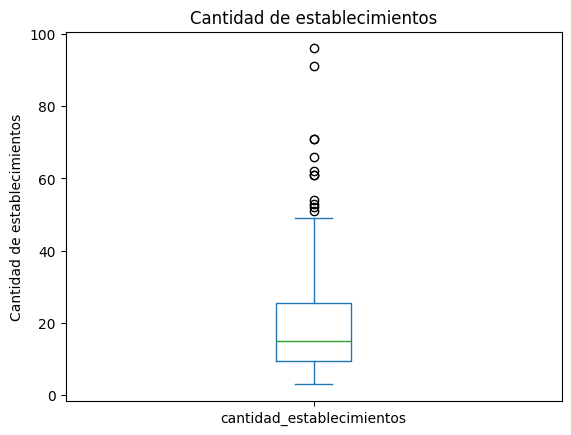

In [ ]:
# Boxplot: cantidad de establecimientos
base_analisis["cantidad_establecimientos"].plot.box()

plt.title("Cantidad de establecimientos")
plt.ylabel("Cantidad de establecimientos")
plt.show()

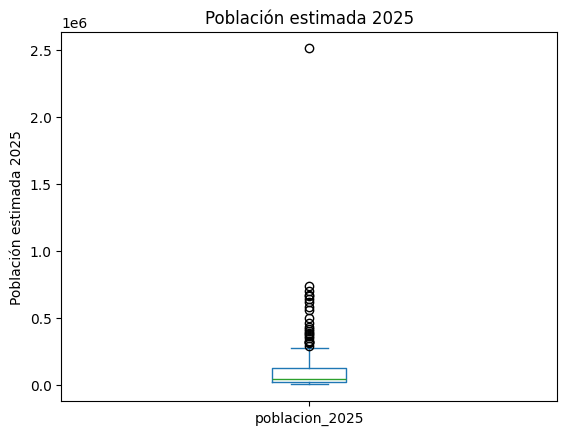

In [ ]:
# Boxplot: población estimada 2025
base_analisis["poblacion_2025"].plot.box()

plt.title("Población estimada 2025")
plt.ylabel("Población estimada 2025")
plt.show()

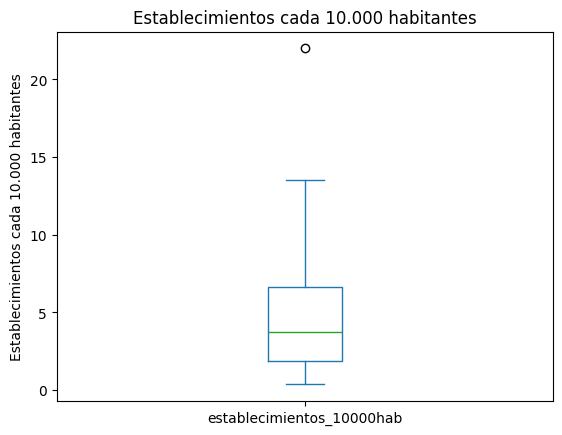

In [ ]:
# Boxplot: establecimientos cada 10.000 habitantes
base_analisis["establecimientos_10000hab"].plot.box()

plt.title("Establecimientos cada 10.000 habitantes")
plt.ylabel("Establecimientos cada 10.000 habitantes")
plt.show()

Los boxplots muestran la presencia de valores atípicos en las variables analizadas. En la cantidad de establecimientos se observan partidos con valores superiores al resto, lo que indica una mayor cantidad absoluta de establecimientos de salud en determinados territorios.

En la población estimada para 2025, la caja aparece comprimida y se observan numerosos valores atípicos superiores. Esto refleja la fuerte heterogeneidad poblacional entre partidos, con algunos considerablemente más poblados que la mayoría.

En el indicador de establecimientos cada 10.000 habitantes se identifica un valor atípico superior. Este caso no se interpreta necesariamente como un error, sino como un partido con una disponibilidad relativa de establecimientos mayor al resto.

Dado que los valores atípicos pueden representar diferencias territoriales reales, no se eliminan del análisis.

In [ ]:
# Identificación de valor atípico superior en el indicador relativo
base_analisis[
    base_analisis["establecimientos_10000hab"] > 15
]

,partido,partido_norm,cantidad_establecimientos,geometry,poblacion_2025,establecimientos_10000hab
123,Tordillo,tordillo,4.0,"MULTIPOLYGON (((-57.42 -36.16, -57.42 -36.16, ...",1818.0,22.0022


El análisis de valores extremos permite observar que algunos partidos pueden presentar una cobertura relativa elevada no necesariamente por tener muchos establecimientos, sino por contar con una población reducida. Este es el caso de Tordillo, que con 4 establecimientos alcanza un indicador alto de 22 establecimientos cada 10.000 habitantes. Por este motivo, los resultados deben interpretarse considerando conjuntamente la cantidad absoluta de establecimientos, la población y el indicador relativo.

### Análisis de correlación

Se analiza la correlación entre la población estimada para 2025, la cantidad de establecimientos de salud y el indicador de establecimientos cada 10.000 habitantes. Este análisis permite explorar si los partidos con mayor población tienden a concentrar mayor cantidad de establecimientos y cómo se relaciona esa distribución con la cobertura relativa.

#### Matriz de correlación

In [ ]:
# Matriz de correlación entre variables principales
base_analisis[
    [
        "poblacion_2025",
        "cantidad_establecimientos",
        "establecimientos_10000hab"
    ]
].corr()

,poblacion_2025,cantidad_establecimientos,establecimientos_10000hab
poblacion_2025,1.000000,0.81132,-0.441243
cantidad_establecimientos,0.811320,1.00000,-0.517750
establecimientos_10000hab,-0.441243,-0.51775,1.000000


#### Relación entre población y cantidad de establecimientos

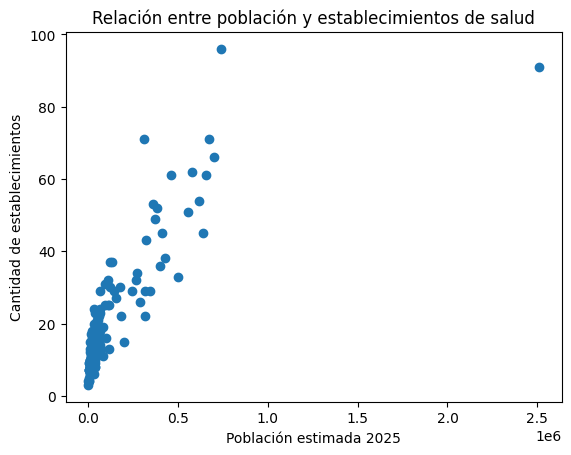

In [ ]:
# Relación entre población y cantidad de establecimientos
plt.scatter(
   base_analisis["poblacion_2025"],
    base_analisis["cantidad_establecimientos"]
)

plt.xlabel("Población estimada 2025")
plt.ylabel("Cantidad de establecimientos")
plt.title("Relación entre población y establecimientos de salud")
plt.show()

#### Relación entre población y cobertura relativa

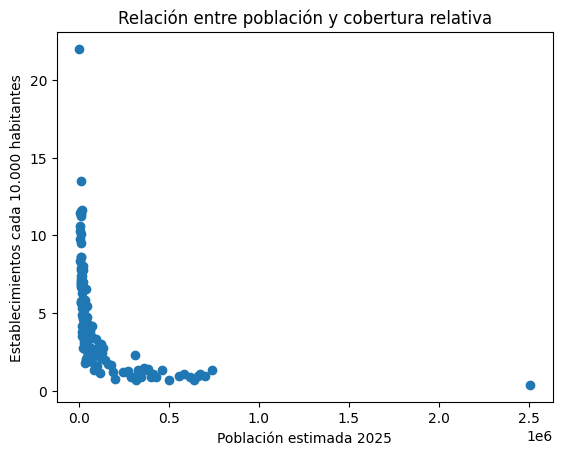

In [ ]:
# Relación entre población y cobertura relativa
plt.scatter(
    base_analisis["poblacion_2025"],
    base_analisis["establecimientos_10000hab"]
)

plt.xlabel("Población estimada 2025")
plt.ylabel("Establecimientos cada 10.000 habitantes")
plt.title("Relación entre población y cobertura relativa")
plt.show()

La matriz de correlación muestra una correlación positiva fuerte entre la población estimada 2025 y la cantidad de establecimientos de salud (`r = 0,81`). Esto indica que, en términos absolutos, los partidos más poblados tienden a concentrar una mayor cantidad de establecimientos.

Sin embargo, la relación entre población y el indicador de establecimientos cada 10.000 habitantes es negativa (`r = -0,44`). Esto significa que una mayor población no implica necesariamente una mayor cobertura relativa. En el gráfico se observa que los partidos menos poblados presentan mayor variabilidad del indicador, mientras que los partidos más poblados tienden a concentrarse en valores bajos de cobertura relativa.

El comportamiento observado puede estar influenciado por algunos partidos de muy baja población, como Tordillo, identificados previamente en el análisis de valores atípicos.

En conjunto, estos resultados sugieren que la distribución absoluta de establecimientos acompaña parcialmente la distribución poblacional. Sin embargo, existen diferencias territoriales en la cobertura sanitaria relativa medida como establecimientos cada 10.000 habitantes.

## Visualización y análisis espacial

En esta etapa se representan espacialmente los indicadores calculados para analizar la distribución territorial de los establecimientos públicos de salud en la Provincia de Buenos Aires. Las visualizaciones permiten identificar diferencias entre partidos y explorar posibles desigualdades en la cobertura relativa de servicios de salud.

### Localización de establecimientos de salud

Se representa la localización puntual de los establecimientos públicos de salud sobre la base geográfica de partidos. Esta visualización permite observar la distribución espacial de los establecimientos y complementar el análisis del indicador poblacional.

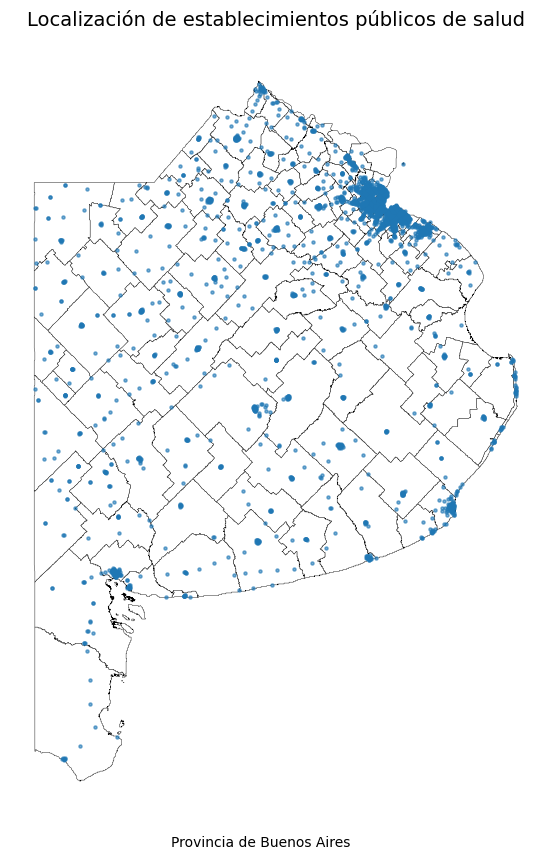

In [ ]:
# Mapa de localización de establecimientos de salud
fig, ax = plt.subplots(figsize=(12, 10))

partidos.plot(
    ax=ax,
    color="white",
    edgecolor="black",
    linewidth=0.3
)

salud.plot(
    ax=ax,
    markersize=5,
    alpha=0.6
)

ax.set_title(
    "Localización de establecimientos públicos de salud",
    fontsize=14,
    pad=15
)

ax.axis("off")

fig.text(
    0.5, 0.08,
    "Provincia de Buenos Aires",
    ha="center",
    fontsize=10
)

plt.show()

El mapa muestra la distribución espacial de los establecimientos públicos de salud en la Provincia de Buenos Aires. Se observa una mayor concentración de puntos en el área metropolitana y en algunos centros urbanos relevantes, mientras que en el interior provincial la distribución aparece más dispersa.
Esta visualización permite identificar patrones territoriales que complementan el análisis de los indicadores realizados previamente.

### Distribución de establecimientos cada 10.000 habitantes

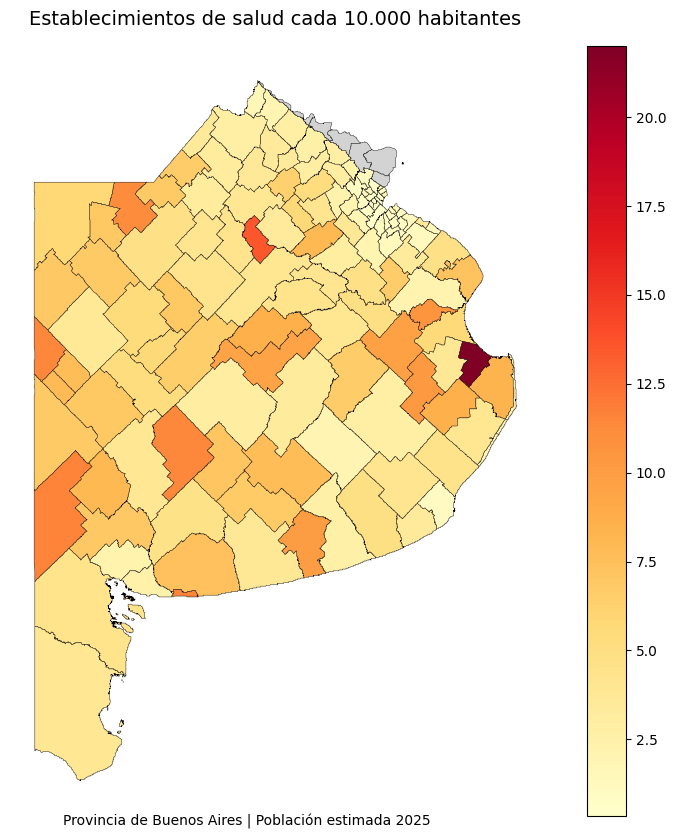

In [ ]:
# Mapa coroplético de establecimientos cada 10.000 habitantes
fig, ax = plt.subplots(figsize=(12, 10))

partidos_indicadores.plot(
    column="establecimientos_10000hab",
    ax=ax,
    legend=True,
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.3,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin dato"
    }
)

ax.set_title(
    "Establecimientos de salud cada 10.000 habitantes",
    fontsize=14,
    loc="center",
    pad=15
)

ax.axis("off")

fig.text(
    0.5, 0.10,
    "Provincia de Buenos Aires | Población estimada 2025",
    ha="center",
    fontsize=10
)

plt.show()

El mapa evidencia diferencias territoriales en la disponibilidad relativa de establecimientos públicos de salud. Los valores más elevados se observan en algunos partidos del interior provincial y en territorios con menor población, mientras que gran parte de los partidos más poblados presentan valores relativamente más bajos del indicador. Estos resultados sugieren que la distribución absoluta de establecimientos no siempre se traduce en una mayor cobertura relativa. Asimismo, los partidos insulares aparecen sin datos debido a la ausencia de información poblacional en la fuente utilizada.


### Mapa interactivo de cobertura sanitaria

Como complemento al mapa coroplético estático, se construye una versión interactiva con la librería `folium`. Este tipo de mapa permite explorar el indicador de establecimientos cada 10.000 habitantes a nivel de partido, consultando el valor exacto de cada uno al pasar el cursor o hacer clic sobre el territorio.

In [ ]:
# Centroide aproximado de la Provincia de Buenos Aires para centrar el mapa
centro_mapa = [-36.7, -60.5]

mapa_interactivo = folium.Map(
    location=centro_mapa,
    zoom_start=6,
    tiles=None
)

# Mapa base gris claro (no requiere clave de acceso)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri",
    name="Esri gris claro"
).add_to(mapa_interactivo)

# Capa coroplética con el indicador de establecimientos cada 10.000 hab.
folium.Choropleth(
    geo_data=partidos_indicadores.dropna(subset=["establecimientos_10000hab"]),
    data=partidos_indicadores.dropna(subset=["establecimientos_10000hab"]),
    columns=["partido", "establecimientos_10000hab"],
    key_on="feature.properties.partido",
    fill_color="YlOrRd",
    fill_opacity=0.8,
    line_opacity=0.3,
    legend_name="Establecimientos cada 10.000 habitantes",
    nan_fill_color="lightgrey"
).add_to(mapa_interactivo)

# Capa de tooltips con el detalle de cada partido al pasar el cursor
folium.GeoJson(
    partidos_indicadores,
    style_function=lambda x: {
        "fillColor": "transparent",
        "color": "transparent"
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["partido", "cantidad_establecimientos", "poblacion_2025", "establecimientos_10000hab"],
        aliases=["Partido:", "Establecimientos:", "Población 2025:", "Establecimientos cada 10.000 hab.:"],
        localize=True
    )
).add_to(mapa_interactivo)

mapa_interactivo

El mapa interactivo permite explorar el patrón observado en la versión estática: algunos partidos del interior presentan valores relativamente altos del indicador, mientras que varios partidos del conurbano bonaerense muestran valores más bajos.

La principal ventaja de esta visualización es que permite consultar el valor exacto del indicador para cada partido de forma individual, sin depender únicamente de la escala de colores. Esto resulta útil para una exploración más detallada por parte de quien consulte el análisis.

### Ranking del indicador de cobertura

Para complementar la lectura del mapa, se identifican los partidos con valores más altos y más bajos del indicador de establecimientos cada 10.000 habitantes.

#### Partidos con mayor disponibilidad relativa

In [ ]:
# Partidos con mayor disponibilidad relativa
top_10_mayor = (
    partidos_indicadores
    .dropna(subset=["establecimientos_10000hab"])
    .sort_values("establecimientos_10000hab", ascending=False)
    [["partido", "cantidad_establecimientos", "poblacion_2025", "establecimientos_10000hab"]]
    .head(10)
)

top_10_mayor

,partido,cantidad_establecimientos,poblacion_2025,establecimientos_10000hab
123,Tordillo,4.0,1818.0,22.002200
62,Alberti,15.0,11107.0,13.504997
112,Puan,17.0,14657.0,11.598554
129,Monte Hermoso,9.0,7769.0,11.584503
107,Pellegrini,7.0,6128.0,11.422977
85,General La Madrid,12.0,10529.0,11.397094
83,General Pinto,13.0,11573.0,11.233042
135,Lezama,7.0,6609.0,10.591617
74,General Guido,3.0,2915.0,10.291595
121,San Cayetano,9.0,8945.0,10.061487


#### Partidos con menor disponibilidad relativa

In [ ]:
# Partidos con menor disponibilidad relativa
top_10_menor = (
    partidos_indicadores
    .dropna(subset=["establecimientos_10000hab"])
    .sort_values("establecimientos_10000hab", ascending=True)
    [["partido", "cantidad_establecimientos", "poblacion_2025", "establecimientos_10000hab"]]
    .head(10)
)

top_10_menor

,partido,cantidad_establecimientos,poblacion_2025,establecimientos_10000hab
2,La Matanza,91.0,2509547.0,0.362615
58,Tigre,33.0,500615.0,0.659189
12,Morón,22.0,316073.0,0.696042
22,Merlo,45.0,639681.0,0.703476
40,Hurlingham,15.0,198509.0,0.755633
55,Tres de Febrero,29.0,344354.0,0.842157
5,Almirante Brown,54.0,616000.0,0.876623
14,General San Martín,38.0,428283.0,0.887264
71,San Isidro,26.0,291097.0,0.893173
3,Esteban Echeverría,36.0,402021.0,0.895476


El ranking permite observar que los valores más altos del indicador se concentran en partidos con baja población absoluta, como Tordillo, Alberti, Puan y Monte Hermoso. En estos casos, una cantidad moderada de establecimientos genera una mayor disponibilidad relativa cada 10.000 habitantes.

En cambio, los valores más bajos se observan principalmente en partidos del conurbano bonaerense o altamente poblados, como La Matanza, Tigre, Morón, Merlo y Almirante Brown. Esto indica que, aunque algunos de estos partidos cuentan con una cantidad absoluta importante de establecimientos, su disponibilidad relativa disminuye al considerar el tamaño poblacional.

#### Visualización del ranking de partidos con menor disponibilidad relativa

Se representa el ranking de los diez partidos con menor valor del indicador de establecimientos públicos de salud cada 10.000 habitantes. Esta visualización complementa el mapa coroplético y permite identificar con mayor claridad los territorios con menor disponibilidad relativa.


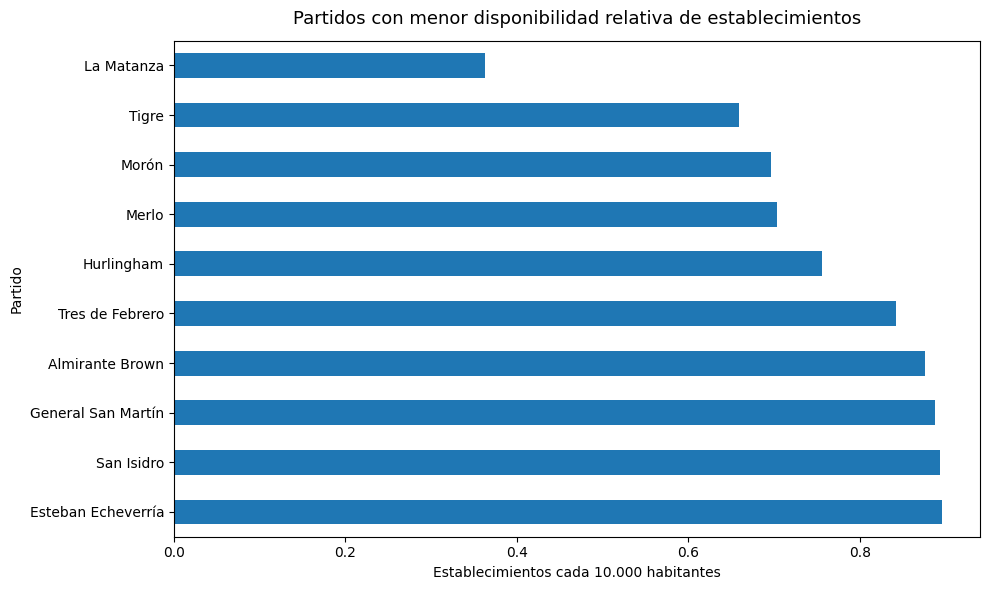

In [ ]:
# Gráfico de barras: partidos con menor disponibilidad relativa
fig, ax = plt.subplots(figsize=(10, 6))

top_10_menor = top_10_menor.sort_values(
    "establecimientos_10000hab",
    ascending=True
)

top_10_menor.plot(
    kind="barh",
    x="partido",
    y="establecimientos_10000hab",
    ax=ax,
    legend=False
)

ax.invert_yaxis()

ax.set_title(
    "Partidos con menor disponibilidad relativa de establecimientos",
    fontsize=13,
    pad=12
)

ax.set_xlabel("Establecimientos cada 10.000 habitantes")
ax.set_ylabel("Partido")

plt.tight_layout()
plt.show()

El gráfico muestra que los valores más bajos del indicador se concentran principalmente en partidos del conurbano bonaerense. La Matanza presenta la menor disponibilidad relativa, seguida por Tigre, Morón y Merlo.

Estos resultados sugieren que, aunque algunos de estos partidos cuentan con una cantidad absoluta importante de establecimientos, la disponibilidad relativa disminuye al considerar el tamaño de su población.

## Conclusiones

El análisis permitió observar que la distribución territorial de los establecimientos públicos de salud en la Provincia de Buenos Aires no es homogénea entre los partidos.

El mapa de localización mostró una mayor concentración de establecimientos en el área metropolitana, el conurbano bonaerense y algunos centros urbanos, mientras que en el interior provincial la distribución resulta más dispersa.

Sin embargo, al relacionar la cantidad de establecimientos con la población estimada para 2025, se observó que los partidos más poblados no necesariamente presentan mayor disponibilidad relativa. En particular, varios partidos del conurbano bonaerense mostraron valores bajos de establecimientos cada 10.000 habitantes, lo que sugiere una menor cobertura relativa en función de su población.

En cambio, algunos partidos con menor población presentaron valores más altos del indicador, aun contando con una menor cantidad absoluta de establecimientos. Esto evidencia la importancia de utilizar indicadores estandarizados por población para interpretar la cobertura territorial.

Como limitación del análisis, algunos partidos insulares no pudieron ser incluidos en el cálculo del indicador debido a la ausencia de información poblacional en la fuente utilizada.

En síntesis, el análisis evidencia que la distribución de establecimientos públicos de salud no acompaña de manera uniforme la distribución poblacional de los partidos de la Provincia de Buenos Aires, identificándose diferencias territoriales relevantes en la disponibilidad relativa de servicios.
